In [16]:
#pip install ucimlrepo

In [17]:
import warnings
warnings.filterwarnings('ignore')

In [18]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
taiwanese_bankruptcy_prediction = fetch_ucirepo(id=572) 
  
# data (as pandas dataframes) 
X = taiwanese_bankruptcy_prediction.data.features 
y = taiwanese_bankruptcy_prediction.data.targets 
  
# metadata 
print(taiwanese_bankruptcy_prediction.metadata) 
  
# variable information 
print(taiwanese_bankruptcy_prediction.variables) 


{'uci_id': 572, 'name': 'Taiwanese Bankruptcy Prediction', 'repository_url': 'https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction', 'data_url': 'https://archive.ics.uci.edu/static/public/572/data.csv', 'abstract': 'The data were collected from the Taiwan Economic Journal  for the years 1999 to 2009. Company bankruptcy was defined based on the business regulations of the Taiwan Stock Exchange.', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 6819, 'num_features': 95, 'feature_types': ['Integer'], 'demographics': [], 'target_col': ['Bankrupt?'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Fri Mar 15 2024', 'dataset_doi': '10.24432/C5004D', 'creators': [], 'intro_paper': None, 'additional_info': {'summary': None, 'purpose': None, 'funded_by': None, 'instances_represent': None, 'recommended_data_splits': None, 'sensitive_data': Non

In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor


In [20]:
X.dtypes

ROA(C) before interest and depreciation before interest    float64
ROA(A) before interest and % after tax                     float64
ROA(B) before interest and depreciation after tax          float64
Operating Gross Margin                                     float64
Realized Sales Gross Margin                                float64
                                                            ...   
Liability to Equity                                        float64
Degree of Financial Leverage (DFL)                         float64
Interest Coverage Ratio (Interest expense to EBIT)         float64
Net Income Flag                                              int64
Equity to Liability                                        float64
Length: 95, dtype: object

In [21]:
y.dtypes

Bankrupt?    int64
dtype: object

In [22]:
np.sum(X.dtypes==object)# to check weather non numeric data

np.int64(0)

In [23]:
np.sum(y.dtypes==object)

np.int64(0)

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


In [33]:
from sklearn.metrics import f1_score, mean_absolute_error
from tqdm import tqdm


features=[2,3,4,5]
n_est=[25,50,100,150,200]
scores=[]
for f in tqdm(features):
    for n in n_est:
        rf=RandomForestClassifier(random_state=42,max_features=f,n_estimators=n)
        rf.fit(X_train,y_train)
        y_pred=rf.predict(X_test)
        scores.append([f,n,f1_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=('Feature',"Tree",'Score'))
df_scores.sort_values('Score',ascending=False)

100%|██████████| 4/4 [00:22<00:00,  5.60s/it]


,Feature,Tree,Score
10,4,25,0.262626
15,5,25,0.241758
6,3,50,0.239130
7,3,100,0.236559
1,2,50,0.224719
16,5,50,0.222222
11,4,50,0.222222
17,5,100,0.219780
4,2,200,0.204545
9,3,200,0.202247


In [34]:
rf=RandomForestClassifier(random_state=42,max_features=4,n_estimators=25)
rf.fit(X_train,y_train)
y_pred=rf.predict(X_test)
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       1.00      0.97      0.98      2025
           1       0.17      0.62      0.26        21

    accuracy                           0.96      2046
   macro avg       0.58      0.79      0.62      2046
weighted avg       0.99      0.96      0.97      2046



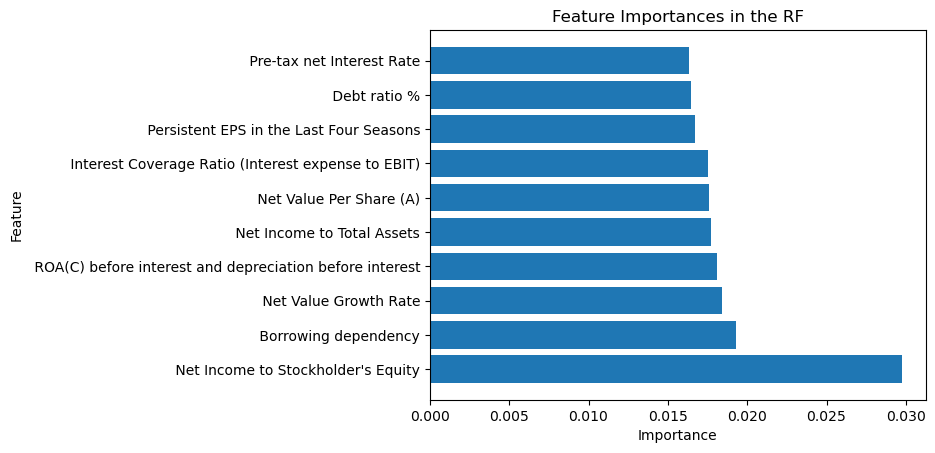

In [35]:
rf=RandomForestClassifier(random_state=42,max_features=4,n_estimators=25)

rf.fit(X, y)
df_imp = pd.DataFrame({"feature": X.columns, "importance": rf.feature_importances_})
df_imp = df_imp.sort_values("importance",ascending=False).iloc[0:10]
import matplotlib.pyplot as plt
plt.barh(df_imp["feature"], df_imp["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importances in the RF")
plt.show()